# Data analysis with R and tidyverse

## How to use this notebook

1. Open this file in JupyterLab, Jupyter Notebook, or VS Code with notebook support.
2. Choose **R (Lecture13)**, or another R kernel with tidyverse installed.
3. Run cells from top to bottom with **Shift + Enter**. A code cell can use objects
   created in earlier cells.
4. Read each output and then change a small part of the example.
5. Try the exercises before opening the [answer section](#practice-answers).

The examples need R, the `tidyverse` package collection, and the four CSV files in
`data/`. Keep that folder beside this notebook. 

The lesson uses relative paths such as `"data/people.csv"`. Run it with the folder
containing `Lecture13.ipynb` as R's working directory. In VS Code, open that folder
as your workspace. `getwd()` shows the current working directory.

If an R kernel is not available, open an **R console** and run the following once:

```r
install.packages("IRkernel")
IRkernel::installspec(user = TRUE)
```

## Roadmap

| Notebook section | Topic |
|---|---|
| 1 | R, tidyverse, and first R expressions |
| 2 | Install and load packages |
| 3 | Import and inspect data |
| 4 | Select columns |
| 5 | Filter rows |
| 6 | Create columns |
| 7 | Connect steps with `%>%` |
| 8 | Comparison and logical operators |
| 9 | Combine tables with joins |
| 10 | Summarize data and groups |
| 11 | Pivot between long and wide tables |
| 12 | Build a plot with ggplot2 |
| 13 | Color points by region |

## 1. R and tidyverse

**R** is a programming language used for data analysis and statistics.
**tidyverse** is a collection of R packages that work well together.
A **package** adds functions and sometimes datasets to R.

| Package | What we use it for |
|---|---|
| `readr` | Read CSV and tab-separated files |
| `dplyr` | Select, filter, transform, join, and summarize tables |
| `tidyr` | Change the shape of a table |
| `ggplot2` | Build plots |

A **function** performs a task. In `mean(c(2, 4, 6))`, `mean()` calculates an average
and `c()` combines values into a **vector**, an ordered collection of values.
The values supplied to a function are its **arguments**.

### A first R example

- `<-` assigns a value to a name.
- `#` starts a comment. R ignores the rest of that line.
- Quotation marks identify text, such as `"Alex"`.
- R is case-sensitive: `age` and `Age` are different names.

In [1]:
# Store a number and then use it in a calculation.
age <- 20
age_next_year <- age + 1
age_next_year

[1] 21

In [2]:
# c() combines three numbers into a vector.
ages <- c(20, 30, 40)
mean(ages)

[1] 30

The first result is `21`. The second result is `30`, the average of the three ages.
R usually displays the final expression in a notebook cell. Use `print()` when you
want to display an intermediate result explicitly.

**Quick check:** Change the first age to `21`, then run that cell again.
What happens to `age_next_year`?

## 2. Install and load packages

**Install** a package to put it on your computer. You usually do this once for a
particular R installation. **Load** a package to make its functions available in
the current R session. Do this again after restarting the kernel.

If tidyverse is missing, remove the `#` from the installation line below and run it.
Installation needs internet access and may take several minutes.

In [3]:
# Run once if needed, then put the # back:
# install.packages("tidyverse")

In [4]:
library(tidyverse)

# These options control plot size inside an R notebook.
options(repr.plot.width = 7, repr.plot.height = 4.5)

Warning message:
“package ‘tidyverse’ was built under R version 4.1.3”


── Attaching packages ─────────────────────────────────────── tidyverse 1.3.2 ──


✔ ggplot2 3.4.2     ✔ purrr   1.2.1
✔ tibble  3.2.1     ✔ dplyr   1.1.1
✔ tidyr   1.3.0     ✔ stringr 1.5.0
✔ readr   2.1.4     ✔ forcats 1.0.0


Warning message:
“package ‘ggplot2’ was built under R version 4.1.3”


Warning message:
“package ‘tibble’ was built under R version 4.1.3”


Warning message:
“package ‘tidyr’ was built under R version 4.1.3”


Warning message:
“package ‘readr’ was built under R version 4.1.3”


Warning message:
“package ‘dplyr’ was built under R version 4.1.3”


Warning message:
“package ‘stringr’ was built under R version 4.1.3”


Warning message:
“package ‘forcats’ was built under R version 4.1.3”


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()


## 3. Import and inspect data

A **table** has rows and columns. Each row in `people` describes one person,
and each column records one variable.

| Column | Meaning |
|---|---|
| `name` | Person's name |
| `age` | Age in years |
| `country` | Example country label |
| `job` | Example job label |
| `region` | Example region, A or B |

A **CSV** file separates fields with commas. `read_csv()` reads a CSV file and
returns a **tibble**, a form of R data frame with convenient printing behavior.
All datasets for this notebook are saved as CSV files in `data/`.

### Read the CSV file

`"data/people.csv"` is the path to the saved people table, relative to the notebook
folder. `show_col_types = FALSE` hides the column-type message so that we can focus
on the table. It does not change the imported data.

In [5]:
people <- read_csv("data/people.csv", show_col_types = FALSE)
people

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Alex,16,USA,Student,A
Blair,18,Canada,Student,A
Casey,20,USA,Student,A
Drew,30,Canada,Teacher,A
Emery,32,USA,Researcher,B
Finley,39,Canada,Nurse,B
Gray,45,USA,Teacher,B
Harper,51,Canada,Researcher,B


### Inspect a table before analyzing it

`dim()` returns the number of rows and columns. `names()` returns column names.
`head()` shows the first rows. `glimpse()` shows the structure and column types.

In [6]:
dim(people)

[1] 8 5

In [7]:
names(people)

[1] "name"    "age"     "country" "job"     "region"

In [8]:
head(people, 3)

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Alex,16,USA,Student,A
Blair,18,Canada,Student,A
Casey,20,USA,Student,A


In [9]:
glimpse(people)

Rows: 8
Columns: 5
$ name    <chr> "Alex", "Blair", "Casey", "Drew", "Emery", "Finley", "Gray", "…
$ age     <dbl> 16, 18, 20, 30, 32, 39, 45, 51
$ country <chr> "USA", "Canada", "USA", "Canada", "USA", "Canada", "USA", "Can…
$ job     <chr> "Student", "Student", "Student", "Teacher", "Researcher", "Nur…
$ region  <chr> "A", "A", "A", "A", "B", "B", "B", "B"


You should find **8 rows and 5 columns**. `age` is numeric; the other columns are
text. In a tibble's output, `<dbl>` means a numeric column and `<chr>` means text.

## 4. Select columns

Use `select()` when you want particular **columns**. The first argument is the
table, followed by the names of the columns to keep.

Inside these dplyr calls, write column names directly, without quotes.
The order of the selected names controls the order of the output columns.

In [10]:
select(people, age)

age
<dbl>
16
18
20
30
32
39
45
51


In [11]:
selected_people <- select(people, name, age, region)
selected_people

name,age,region
<chr>,<dbl>,<chr>
Alex,16,A
Blair,18,A
Casey,20,A
Drew,30,A
Emery,32,B
Finley,39,B
Gray,45,B
Harper,51,B


`selected_people` has 8 rows and 3 columns. `people` still has its original
5 columns: calling `select()` does not change the original object unless you assign
the result back to it.

**Exercise 1:** Make a table called `jobs` containing only `name`, `country`, and
`job`, in that order. Display the result. Keep `people` unchanged.

In [12]:
# Exercise 1: write your code here.
# Hint: jobs <- select(...)

## 5. Filter rows

Use `filter()` when you want particular **rows**. A condition is checked for every
row. Rows for which the condition is `TRUE` are kept.

The comparison `age > 30` means "age is greater than 30." Someone whose age is
exactly 30 is not included. We will compare all the operators in Section 8.

In [13]:
older_than_30 <- filter(people, age > 30)
older_than_30

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Emery,32,USA,Researcher,B
Finley,39,Canada,Nurse,B
Gray,45,USA,Teacher,B
Harper,51,Canada,Researcher,B


In [14]:
# Quotes are needed here because A is a text value, not a column name.
filter(people, region == "A")

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Alex,16,USA,Student,A
Blair,18,Canada,Student,A
Casey,20,USA,Student,A
Drew,30,Canada,Teacher,A


The first result contains **4 people**: Emery, Finley, Gray, and Harper.
Filtering keeps all columns unless you also select columns.

**Exercise 2:** Keep people whose age is at least 30. Store the result as
`age_30_or_more`. You should get 5 rows, including Drew.

Hint: "at least" uses `>=`.

In [15]:
# Exercise 2: write your code here.

## 6. Create or change columns

Use `mutate()` to create a column from existing columns. Write
`new_column_name = calculation` inside the function.

`if_adult = age >= 18` creates a **logical** column containing `TRUE` or `FALSE`.

In [16]:
people_with_adult <- mutate(people, if_adult = age >= 18)
people_with_adult

name,age,country,job,region,if_adult
<chr>,<dbl>,<chr>,<chr>,<chr>,<lgl>
Alex,16,USA,Student,A,FALSE
Blair,18,Canada,Student,A,TRUE
Casey,20,USA,Student,A,TRUE
Drew,30,Canada,Teacher,A,TRUE
Emery,32,USA,Researcher,B,TRUE
Finley,39,Canada,Nurse,B,TRUE
Gray,45,USA,Teacher,B,TRUE
Harper,51,Canada,Researcher,B,TRUE


In [17]:
# mutate() can create more than one column in the same call.
people_next_year <- mutate(
  people,
  if_adult = age >= 18,
  age_next_year = age + 1
)
people_next_year

name,age,country,job,region,if_adult,age_next_year
<chr>,<dbl>,<chr>,<chr>,<chr>,<lgl>,<dbl>
Alex,16,USA,Student,A,FALSE,17
Blair,18,Canada,Student,A,TRUE,19
Casey,20,USA,Student,A,TRUE,21
Drew,30,Canada,Teacher,A,TRUE,31
Emery,32,USA,Researcher,B,TRUE,33
Finley,39,Canada,Nurse,B,TRUE,40
Gray,45,USA,Teacher,B,TRUE,46
Harper,51,Canada,Researcher,B,TRUE,52


`mutate()` keeps the rows and the existing columns. If you use an existing column
name, its values are replaced in the result.

**Exercise 3:** Create `age_in_months` by multiplying `age` by 12. Store the new table
as `people_months` and show just `name`, `age`, and `age_in_months`.

In [18]:
# Exercise 3: write your code here.
# Hint: first mutate(), then select(). Two separate statements are fine.

## 7. Connect steps with the pipe

The pipe `%>%` passes the result on its left into the function on its right,
usually as the first argument. Read it as **"then."**

These two expressions do the same thing:

```r
select(people, name, age)
people %>% select(name, age)
```

### First, use intermediate objects

First choose columns including name, age, country and job, then keep ages greater than 18.

In [19]:
selected_columns <- select(people, name, age, country, job)
tidy_with_steps <- filter(selected_columns, age > 18)
tidy_with_steps

name,age,country,job
<chr>,<dbl>,<chr>,<chr>
Casey,20,USA,Student
Drew,30,Canada,Teacher
Emery,32,USA,Researcher
Finley,39,Canada,Nurse
Gray,45,USA,Teacher
Harper,51,Canada,Researcher


### Now, write the same steps as a pipeline

Place `%>%` at the end of a line so R knows that the expression continues.
You no longer need to repeat the table name at every step.

In [20]:
tidy_with_pipe <- people %>%
  select(name, age, country, job) %>%
  filter(age > 18)

tidy_with_pipe

name,age,country,job
<chr>,<dbl>,<chr>,<chr>
Casey,20,USA,Student
Drew,30,Canada,Teacher
Emery,32,USA,Researcher
Finley,39,Canada,Nurse
Gray,45,USA,Teacher
Harper,51,Canada,Researcher


In [21]:
# TRUE means that both methods produced the same table.
identical(tidy_with_steps, tidy_with_pipe)

[1] TRUE

**Exercise 4:** In one pipeline, keep people whose age is at least 18, create
`age_next_year`, and display `name`, `age`, and `age_next_year`.
Use a new result name such as `adult_preview`.

In [22]:
# Exercise 4: write your code here.
# Suggested order: people -> filter() -> mutate() -> select()

## 8. Comparison and logical operators

A comparison produces `TRUE` or `FALSE` for each value. Logical operators combine
or reverse those comparisons.

| Operator | Meaning | Example |
|---|---|---|
| `==` | Equal to | `region == "A"` |
| `!=` | Not equal to | `region != "A"` |
| `>` | Greater than | `age > 30` |
| `>=` | Greater than or equal to | `age >= 30` |
| `<` | Less than | `age < 30` |
| `<=` | Less than or equal to | `age <= 30` |
| `&` | AND: both conditions must be true | `age >= 18 & region == "A"` |
| `\|` | OR: at least one condition must be true | `age < 18 \| region == "B"` |
| `!` | NOT: reverse a logical value | `!(region == "A")` |

Use `==` to compare values. A single `=` names
an argument in a function call; it is not an equality test.

In [23]:
# AND: both conditions must hold for the same row.
people %>%
  filter(age >= 18 & region == "A")

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Blair,18,Canada,Student,A
Casey,20,USA,Student,A
Drew,30,Canada,Teacher,A


In [24]:
# Commas between filter conditions also mean AND.
people %>%
  filter(age >= 18, region == "A")

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Blair,18,Canada,Student,A
Casey,20,USA,Student,A
Drew,30,Canada,Teacher,A


In [25]:
# OR: keep a person if either condition is true.
people %>%
  filter(age < 18 | region == "B")

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Alex,16,USA,Student,A
Emery,32,USA,Researcher,B
Finley,39,Canada,Nurse,B
Gray,45,USA,Teacher,B
Harper,51,Canada,Researcher,B


In [26]:
# NOT: keep rows that are not in region A.
people %>%
  filter(!(region == "A"))

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Emery,32,USA,Researcher,B
Finley,39,Canada,Nurse,B
Gray,45,USA,Teacher,B
Harper,51,Canada,Researcher,B


**Exercise 5:** Keep people aged 18 through 30, including both endpoints, who
are in region A. Display `name`, `age`, and `region`.
You should find Blair, Casey, and Drew.

In [27]:
# Exercise 5: write your code here.
# Hint: combine age >= 18, age <= 30, and region == "A".

## 9. Combine tables with joins

A **join** combines columns from two tables by matching a shared identifier,
called a **key**. Here the identifier is a person's name, so we use `by = "name"`.

Read the saved annotation table, which contains one row per person. We will reuse
it for all the join examples and the lookup-table exercise.

To show how joins handle unmatched rows, make two small subsets: `x` leaves out
Harper and `y` leaves out Alex. The other six people appear in both tables.

In [28]:
people_annotations <- read_csv("data/people_annotations.csv", show_col_types = FALSE)

x <- people %>%
  select(name, age) %>%
  filter(name != "Harper")

y <- people_annotations %>%
  select(name, region_description) %>%
  filter(name != "Alex")

x

name,age
<chr>,<dbl>
Alex,16
Blair,18
Casey,20
Drew,30
Emery,32
Finley,39
Gray,45


In [29]:
y

name,region_description
<chr>,<chr>
Blair,Example region A
Casey,Example region A
Drew,Example region A
Emery,Example region B
Finley,Example region B
Gray,Example region B
Harper,Example region B


| Join | Rows kept | Result in this example |
|---|---|---|
| `inner_join(x, y)` | Matches found in both tables | 6 people: neither Alex nor Harper |
| `left_join(x, y)` | All rows from x, plus matching information from y | 7 people, including Alex |
| `right_join(x, y)` | All rows from y, plus matching information from x | 7 people, including Harper |
| `full_join(x, y)` | Rows from either table | All 8 people |

Unmatched information is filled with `NA`. For example, Alex has no description
in `y`, and Harper has no age in `x`.

In [30]:
inner_join(x, y, by = "name")

name,age,region_description
<chr>,<dbl>,<chr>
Blair,18,Example region A
Casey,20,Example region A
Drew,30,Example region A
Emery,32,Example region B
Finley,39,Example region B
Gray,45,Example region B


In [31]:
left_join(x, y, by = "name")

name,age,region_description
<chr>,<dbl>,<chr>
Alex,16,NA
Blair,18,Example region A
Casey,20,Example region A
Drew,30,Example region A
Emery,32,Example region B
Finley,39,Example region B
Gray,45,Example region B


In [32]:
right_join(x, y, by = "name")

name,age,region_description
<chr>,<dbl>,<chr>
Blair,18,Example region A
Casey,20,Example region A
Drew,30,Example region A
Emery,32,Example region B
Finley,39,Example region B
Gray,45,Example region B
Harper,NA,Example region B


In [33]:
full_join(x, y, by = "name")

name,age,region_description
<chr>,<dbl>,<chr>
Alex,16,NA
Blair,18,Example region A
Casey,20,Example region A
Drew,30,Example region A
Emery,32,Example region B
Finley,39,Example region B
Gray,45,Example region B
Harper,NA,Example region B


### Add annotations to the complete people table

The saved annotation table has one row per name. Each person therefore matches
one annotation row. First inspect the full lookup table, then join it to `people`.
This adds both a region description and a country code.

In [34]:
people_annotations

name,region_description,country_code
<chr>,<chr>,<chr>
Alex,Example region A,US
Blair,Example region A,CA
Casey,Example region A,US
Drew,Example region A,CA
Emery,Example region B,US
Finley,Example region B,CA
Gray,Example region B,US
Harper,Example region B,CA


In [35]:
people_labeled <- people %>%
  left_join(people_annotations, by = "name")

people_labeled

name,age,country,job,region,region_description,country_code
<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
Alex,16,USA,Student,A,Example region A,US
Blair,18,Canada,Student,A,Example region A,CA
Casey,20,USA,Student,A,Example region A,US
Drew,30,Canada,Teacher,A,Example region A,CA
Emery,32,USA,Researcher,B,Example region B,US
Finley,39,Canada,Nurse,B,Example region B,CA
Gray,45,USA,Teacher,B,Example region B,US
Harper,51,Canada,Researcher,B,Example region B,CA


**Check the key before joining.** If a lookup table repeats a key, one input row
can match several rows and the result can grow. A left join keeps every original
row, but it does not always keep the original row count.
See the [dplyr join documentation](https://dplyr.tidyverse.org/reference/mutate-joins.html).

**Exercise 6:** Reuse `people_annotations` to make a smaller lookup table called
`country_info` with just `name` and `country_code`. Join it to `people` by `name`,
keeping every person. Your result should contain 8 rows and one new column,
`country_code`.

In [36]:
# Exercise 6: write your code here.
# Hint: select() the lookup columns, then use left_join(..., by = "name").

## 10. Summarize data and groups

`mutate()` adds values for individual rows. `summarize()` calculates a smaller
table of summary values, such as one average for the whole table.

### Summarize the whole table

- `min(age)` finds the smallest age.
- `mean(age)` calculates the average age.
- `n()` counts rows in the current table or group.

In [37]:
overall_summary <- people %>%
  summarize(
    min_age = min(age),
    mean_age = mean(age),
    n_samples = n()
  )

overall_summary

min_age,mean_age,n_samples
<dbl>,<dbl>,<int>
16,31.375,8


### Summarize each region separately

`group_by(region)` marks rows as belonging to groups. It does not calculate a
summary by itself. The following `summarize()` runs once for each group.
`.groups = "drop"` returns an ungrouped result for later steps.

In [38]:
region_means <- people %>%
  group_by(region) %>%
  summarize(
    mean_age = mean(age),
    n_people = n(),
    .groups = "drop"
  )

region_means

region,mean_age,n_people
<chr>,<dbl>,<int>
A,21.00,4
B,41.75,4


### Standard deviation and standard error

**Standard deviation (SD)** describes how spread out individual values are.
**Standard error (SE)** describes uncertainty in an estimated mean under the usual
independent-observation sampling assumptions. They are different quantities.

For this example, the estimated SE of the mean is:

**SE = SD / square root of n**

`sd()` computes the sample standard deviation and `sqrt()` computes a square root.
A group needs at least two nonmissing values for a sample SD and this SE calculation.
Our practice ages have no missing values, so `n()` is the number of ages used.

In [39]:
region_summary <- people %>%
  group_by(region) %>%
  summarize(
    n_people = n(),
    mean_age = mean(age),
    sd_age = sd(age),
    se_age = sd(age) / sqrt(n()),
    .groups = "drop"
  )

region_summary

region,n_people,mean_age,sd_age,se_age
<chr>,<int>,<dbl>,<dbl>,<dbl>
A,4,21.00,6.218253,3.109126
B,4,41.75,8.139410,4.069705


Each region has 4 people. The means are **21** for A and **41.75** for B.

If ages can be missing, `mean(age, na.rm = TRUE)` removes missing ages before
averaging. For SE, also count only the nonmissing ages with `sum(!is.na(age))`.
Using `n()` in that case would include rows whose age is missing.

**Exercise 7:** Group by `country` and report the number of people and their mean
age. Return an ungrouped table. Expect 4 people in each country.

In [40]:
# Exercise 7: write your code here.

## 11. Pivot between long and wide tables

Read `data/country_metrics.csv`. Each row records a metric for one country and year.

In **long format**, each row contains a country, a year, and one metric value.
In **wide format**, each year has a separate column. Pivoting changes the layout;
it does not change these measurement values.

We read `year` as text with `col_character()` because the pivot example later
extracts year labels from column names. The other column types are detected
normally. This lets us compare the original and reshaped tables exactly.

In [41]:
data_long <- read_csv(
  "data/country_metrics.csv",
  col_types = cols(year = col_character()),
  show_col_types = FALSE
)

data_long

country,year,metric
<chr>,<chr>,<dbl>
x,1960,10
x,1970,13
x,2010,15
y,1960,20
y,1970,23
y,2010,25
z,1960,30
z,1970,33
z,2010,35


### Long to wide: `pivot_wider()`

- `names_from = year`: use year values to create column names.
- `names_prefix = "yr"`: put `yr` in front of each name.
- `values_from = metric`: put the metric values in those columns.
- `country` remains the identifier for each output row.

In [42]:
data_wide <- pivot_wider(
  data_long,
  names_from = year,
  names_prefix = "yr",
  values_from = metric
)

data_wide

country,yr1960,yr1970,yr2010
<chr>,<dbl>,<dbl>,<dbl>
x,10,13,15
y,20,23,25
z,30,33,35


The 9-row table becomes a 3-row table with the columns `country`, `yr1960`,
`yr1970`, and `yr2010`.

### Wide to long: `pivot_longer()`

- `cols = yr1960:yr2010`: reshape all columns from `yr1960` through `yr2010`.
- `names_to = "year"`: store their names in a new `year` column.
- `names_prefix = "yr"`: remove the `yr` prefix from those names.
- `values_to = "metric"`: store the measurements in a new `metric` column.

In [43]:
long_again <- pivot_longer(
  data_wide,
  cols = yr1960:yr2010,
  names_to = "year",
  names_prefix = "yr",
  values_to = "metric"
)

long_again

country,year,metric
<chr>,<chr>,<dbl>
x,1960,10
x,1970,13
x,2010,15
y,1960,20
y,1970,23
y,2010,25
z,1960,30
z,1970,33
z,2010,35


In [44]:
# Compare plain tibbles so CSV-reader metadata does not affect the check.
identical(as_tibble(data_long), as_tibble(long_again))

[1] TRUE

The result is `TRUE`. `as_tibble()` converts each result to a plain tibble before
comparison. We read the original years as text because `pivot_longer()`
gets them from column names, which are text. To make years integers, you could
use `mutate(year = as.integer(year))` afterward.

Each country/year pair is unique here. If several rows have the same pair,
`pivot_wider()` needs an additional identifier or an explicit rule for combining
values.
See the [tidyr pivot documentation](https://tidyr.tidyverse.org/reference/pivot_longer.html).

**Exercise 8:** Starting from `data_long`, keep only the year `"2010"`, then display
`country` and `metric`. Expect the values 15, 25, and 35.

In [45]:
# Exercise 8: write your code here.

## 12. Build a plot with ggplot2

A ggplot is built from components:

| Component | Role |
|---|---|
| `ggplot(data)` | Choose the table |
| `aes(x = ..., y = ...)` | Map columns to visual properties |
| `geom_point()` | Draw a point for each row |
| `labs()` | Add readable labels and a title |
| `theme_classic()` | Choose the overall appearance |

The `+` operator adds plot components. The `%>%` operator passes data through
analysis steps. 

### Practice data for the scatter plot

Read `data/measurements.csv` once and reuse it for every plot below.
Each row is one example observation with `weight`, `height`, and `region`.
For this exercise, interpret weight in kilograms and height in centimeters.

In [46]:
measurements <- read_csv("data/measurements.csv", show_col_types = FALSE)
head(measurements)

region,weight,height
<chr>,<dbl>,<dbl>
A,48,154
A,52,162
A,57,158
A,61,169
A,65,164
A,69,172


### Map two columns and draw points

Here `weight` goes on the horizontal x-axis and `height` goes on the vertical
y-axis. A point represents one row of `measurements`.

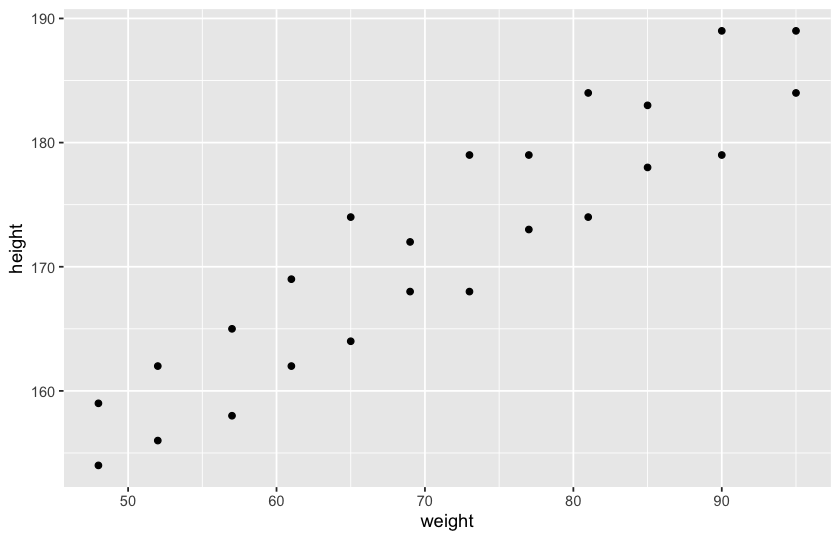

In [47]:
ggplot(measurements) +
  aes(x = weight, y = height) +
  geom_point()

### Add labels and a theme

We can save a plot as an object, just as we save a table. Printing its name displays it.

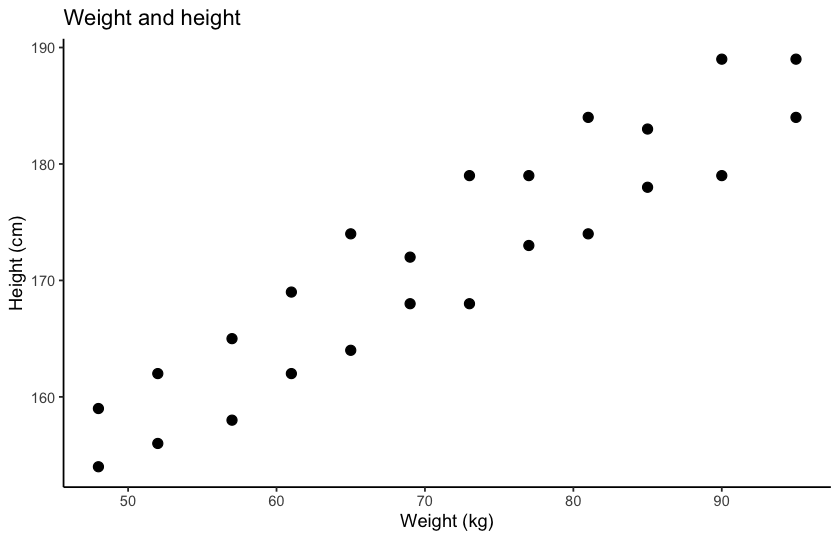

In [48]:
base_plot <- ggplot(measurements, aes(x = weight, y = height)) +
  geom_point(size = 2.5) +
  labs(
    title = "Weight and height",
    x = "Weight (kg)",
    y = "Height (cm)"
  ) +
  theme_classic()

base_plot

The example values tend to increase together. 

**Quick check:** Swap the x and y mappings in the previous cell. Which labels
also need to change?

## 13. Color points by region

Put `color = region` **inside `aes()`** to give points colors based on a column.
ggplot2 creates a legend because the colors represent data values.

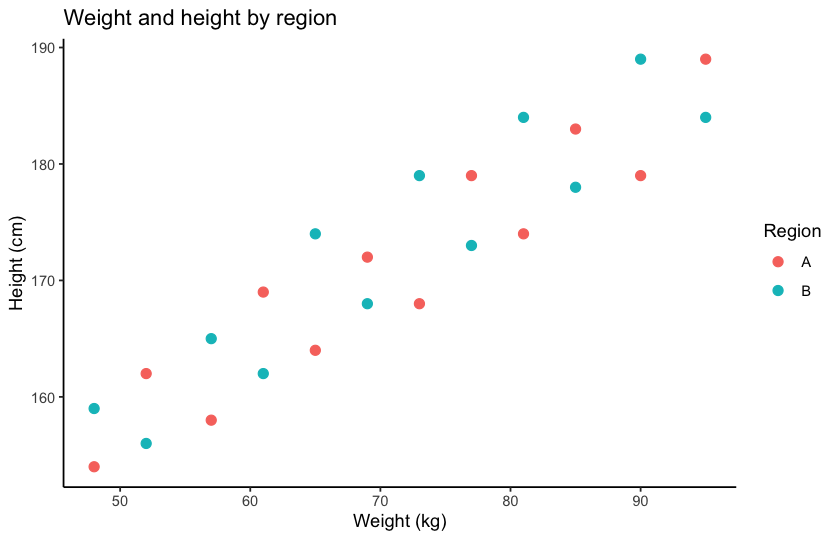

In [49]:
region_plot <- ggplot(measurements, aes(x = weight, y = height)) +
  geom_point(aes(color = region), size = 2.5) +
  labs(
    title = "Weight and height by region",
    x = "Weight (kg)",
    y = "Height (cm)",
    color = "Region"
  ) +
  theme_classic()

region_plot

To give every point the same color, set the color **outside `aes()`**:

```r
geom_point(color = "steelblue")
```

Here `"steelblue"` is a fixed appearance choice, not a column to map.

### Combine dplyr and ggplot2

Read the next example as: start with the measurements, then keep region A,
then pass that smaller table to `ggplot()`. Add the plot layers with `+`.

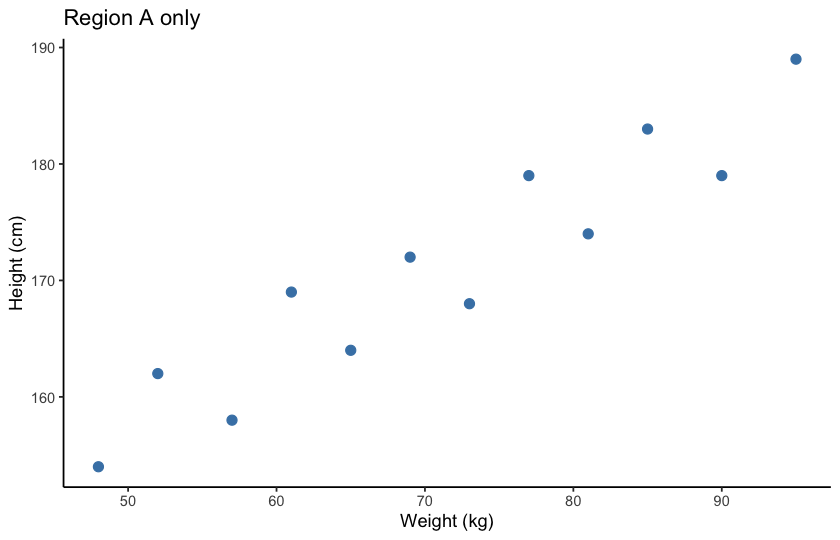

In [50]:
measurements %>%
  filter(region == "A") %>%
  ggplot(aes(x = weight, y = height)) +
  geom_point(color = "steelblue", size = 2.5) +
  labs(
    title = "Region A only",
    x = "Weight (kg)",
    y = "Height (cm)"
  ) +
  theme_classic()

### Optional extension: facets

A **facet** splits a plot into panels using a categorical column. The `~ region`
syntax tells `facet_wrap()` which column defines the panels. The panels below
use the same axis scales, so they are easy to compare.

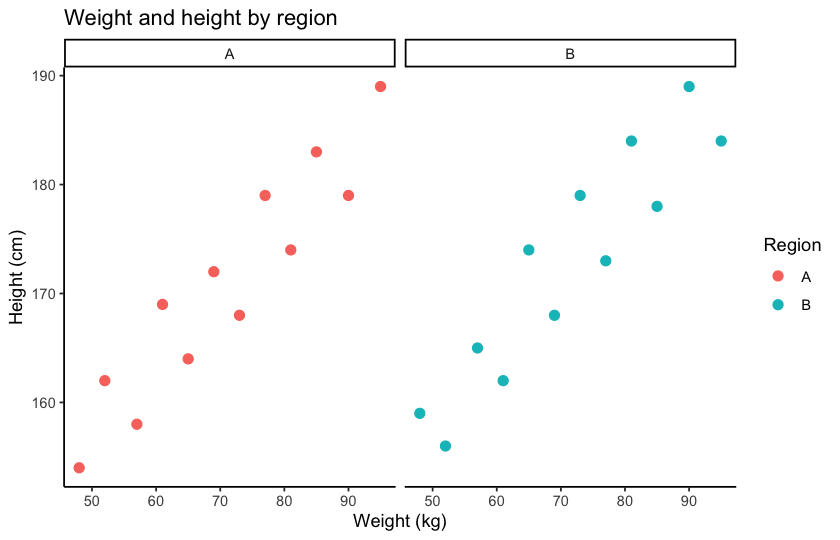

In [51]:
region_plot +
  facet_wrap(~ region)

**Exercise 9:** Plot only rows with `weight >= 70`. Put weight on the x-axis,
height on the y-axis, and map color to region. Add clear axis labels and the title
`"Observations with weight at least 70 kg"`. Use `theme_classic()`.

You should plot 12 points: 6 from each region.

In [52]:
# Exercise 9: write your code here.
# Hint: filter() with %>%, then ggplot(), then layers joined with +.

### Final practice: put the steps together

Starting with `people`:

1. Keep people aged at least 18.
2. Group them by region.
3. Report the number of people and the mean age in each region.
4. Sort the result from largest mean age to smallest.

Use one pipeline. Predict which region will appear first before running the code.

In [53]:
# Final practice: write your code here.

<a id="practice-answers"></a>
# Practice answers

Try the exercises before reading this section. These are worked examples;
other code can produce the same correct results. The answers use new object names
so they do not replace your exercise results.

## Answer 1: select columns

In [54]:
answer_1 <- select(people, name, country, job)
answer_1

name,country,job
<chr>,<chr>,<chr>
Alex,USA,Student
Blair,Canada,Student
Casey,USA,Student
Drew,Canada,Teacher
Emery,USA,Researcher
Finley,Canada,Nurse
Gray,USA,Teacher
Harper,Canada,Researcher


## Answer 2: include the boundary value

`>= 30` includes Drew, whose age is exactly 30.

In [55]:
answer_2 <- filter(people, age >= 30)
answer_2

name,age,country,job,region
<chr>,<dbl>,<chr>,<chr>,<chr>
Drew,30,Canada,Teacher,A
Emery,32,USA,Researcher,B
Finley,39,Canada,Nurse,B
Gray,45,USA,Teacher,B
Harper,51,Canada,Researcher,B


## Answer 3: create a numeric column

In [56]:
answer_3 <- mutate(people, age_in_months = age * 12)
select(answer_3, name, age, age_in_months)

name,age,age_in_months
<chr>,<dbl>,<dbl>
Alex,16,192
Blair,18,216
Casey,20,240
Drew,30,360
Emery,32,384
Finley,39,468
Gray,45,540
Harper,51,612


## Answer 4: combine transformations

In [57]:
answer_4 <- people %>%
  filter(age >= 18) %>%
  mutate(age_next_year = age + 1) %>%
  select(name, age, age_next_year)

answer_4

name,age,age_next_year
<chr>,<dbl>,<dbl>
Blair,18,19
Casey,20,21
Drew,30,31
Emery,32,33
Finley,39,40
Gray,45,46
Harper,51,52


## Answer 5: combine conditions

Commas in `filter()` require all three conditions to hold for the same row.

In [58]:
answer_5 <- people %>%
  filter(age >= 18, age <= 30, region == "A") %>%
  select(name, age, region)

answer_5

name,age,region
<chr>,<dbl>,<chr>
Blair,18,A
Casey,20,A
Drew,30,A


## Answer 6: join a lookup table

In [59]:
answer_country_info <- people_annotations %>%
  select(name, country_code)

answer_6 <- people %>%
  left_join(answer_country_info, by = "name")

answer_6

name,age,country,job,region,country_code
<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
Alex,16,USA,Student,A,US
Blair,18,Canada,Student,A,CA
Casey,20,USA,Student,A,US
Drew,30,Canada,Teacher,A,CA
Emery,32,USA,Researcher,B,US
Finley,39,Canada,Nurse,B,CA
Gray,45,USA,Teacher,B,US
Harper,51,Canada,Researcher,B,CA


## Answer 7: summarize groups

The mean age is 28.25 for USA and 34.5 for Canada in this practice table.

In [60]:
answer_7 <- people %>%
  group_by(country) %>%
  summarize(
    n_people = n(),
    mean_age = mean(age),
    .groups = "drop"
  )

answer_7

country,n_people,mean_age
<chr>,<int>,<dbl>
Canada,4,34.50
USA,4,28.25


## Answer 8: select one year

The years in `data_long` are text, so the comparison uses `"2010"`.

In [61]:
answer_8 <- data_long %>%
  filter(year == "2010") %>%
  select(country, metric)

answer_8

country,metric
<chr>,<dbl>
x,15
y,25
z,35


## Answer 9: filter, then plot

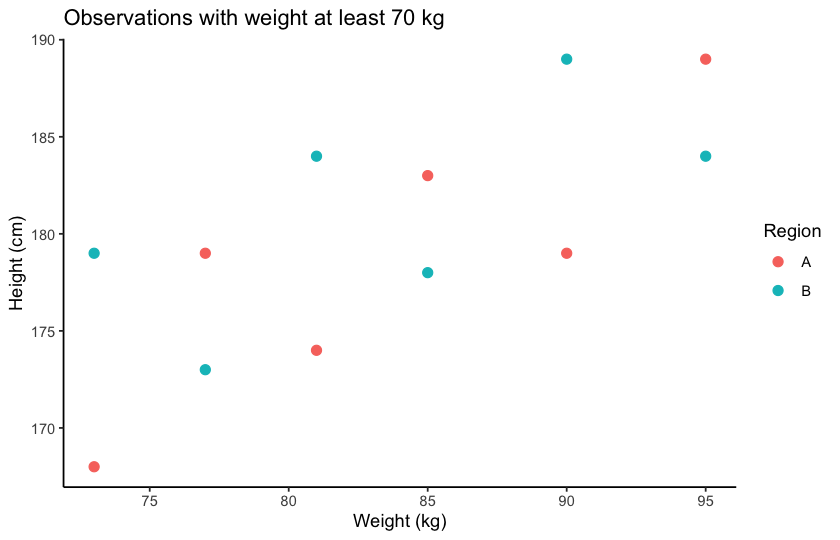

In [62]:
answer_9 <- measurements %>%
  filter(weight >= 70) %>%
  ggplot(aes(x = weight, y = height, color = region)) +
  geom_point(size = 2.5) +
  labs(
    title = "Observations with weight at least 70 kg",
    x = "Weight (kg)",
    y = "Height (cm)",
    color = "Region"
  ) +
  theme_classic()

answer_9

## Answer to the final practice

Region B comes first: its mean age is 41.75. Region A has three included people,
with a mean age of about 22.67.

In [63]:
answer_final <- people %>%
  filter(age >= 18) %>%
  group_by(region) %>%
  summarize(
    n_people = n(),
    mean_age = mean(age),
    .groups = "drop"
  ) %>%
  arrange(desc(mean_age))

answer_final

region,n_people,mean_age
<chr>,<int>,<dbl>
B,4,41.75000
A,3,22.66667
